In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
url = 'https://raw.githubusercontent.com/shivang98/Social-Network-ads-Boost/master/Social_Network_Ads.csv'
df = pd.read_csv(url)

In [41]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [42]:
df = df[['Age', 'EstimatedSalary', 'Purchased']]
df.sample(5)

,Age,EstimatedSalary,Purchased
327,42,75000,0
138,28,59000,0
84,30,62000,0
293,37,77000,0
262,55,125000,1


# Train test split

In [43]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Purchased', axis=1),
                                                    df['Purchased'],
                                                    test_size=0.3,
                                                    random_state=3)
X_train.shape, X_test.shape

((280, 2), (120, 2))

# StandardScaler

In [44]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [45]:
scaler.mean_

array([3.78071429e+01, 6.98142857e+04])

In [46]:
X_train

,Age,EstimatedSalary
236,40,57000
65,24,58000
286,37,62000
180,26,16000
323,48,30000
...,...,...
256,41,72000
131,33,31000
249,35,97000
152,31,76000


In [47]:
X_train_scaled

array([[ 0.20477268, -0.38318707],
       [-1.28933414, -0.35328395],
       [-0.07537235, -0.23367149],
       [-1.10257079, -1.6092148 ],
       [ 0.95182608, -1.19057119],
       [-1.19595247,  0.30458459],
       [ 0.29815435,  0.03545655],
       [-0.44889906,  2.36789956],
       [ 1.41873446,  0.36439082],
       [-0.07537235, -0.53270264],
       [ 1.04520776,  0.1251659 ],
       [ 1.04520776, -0.92144315],
       [-1.47609749, -0.20376837],
       [-1.75624252,  0.00555344],
       [-1.47609749, -1.28028053],
       [ 0.01800932,  1.26148429],
       [ 1.88564284,  0.93255002],
       [-1.47609749, -1.54940857],
       [ 0.111391  , -0.2635746 ],
       [-0.2621357 ,  1.14187183],
       [-1.75624252,  0.18497213],
       [-0.07537235,  0.06535967],
       [ 0.29815435,  0.06535967],
       [-0.2621357 ,  0.06535967],
       [-0.07537235, -0.50279953],
       [ 1.32535279,  0.60361575],
       [ 0.01800932,  0.30458459],
       [ 0.20477268, -0.32338084],
       [ 1.69887949,

In [48]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [49]:
X_train_scaled


,Age,EstimatedSalary
0,0.204773,-0.383187
1,-1.289334,-0.353284
2,-0.075372,-0.233671
3,-1.102571,-1.609215
4,0.951826,-1.190571
...,...,...
275,0.298154,0.065360
276,-0.448899,-1.160668
277,-0.262136,0.812938
278,-0.635662,0.184972


In [50]:
np.round(X_train.describe(), 1)

,Age,EstimatedSalary
count,280.0,280.0
mean,37.8,69814.3
std,10.7,33501.2
min,18.0,15000.0
25%,29.8,44000.0
50%,37.0,70000.0
75%,46.0,88000.0
max,60.0,150000.0


In [51]:
np.round(X_train_scaled.describe(), 1)

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.8,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.1,2.4


# effect of scaling

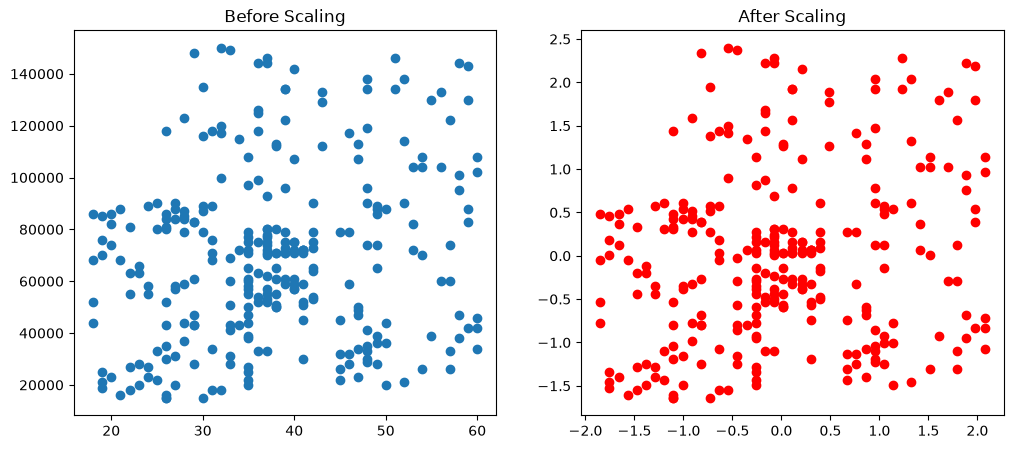

In [52]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color='red')
ax2.set_title("After Scaling")
plt.show()

<Axes: title={'center': 'After Standard Scaling'}, xlabel='Age', ylabel='Density'>

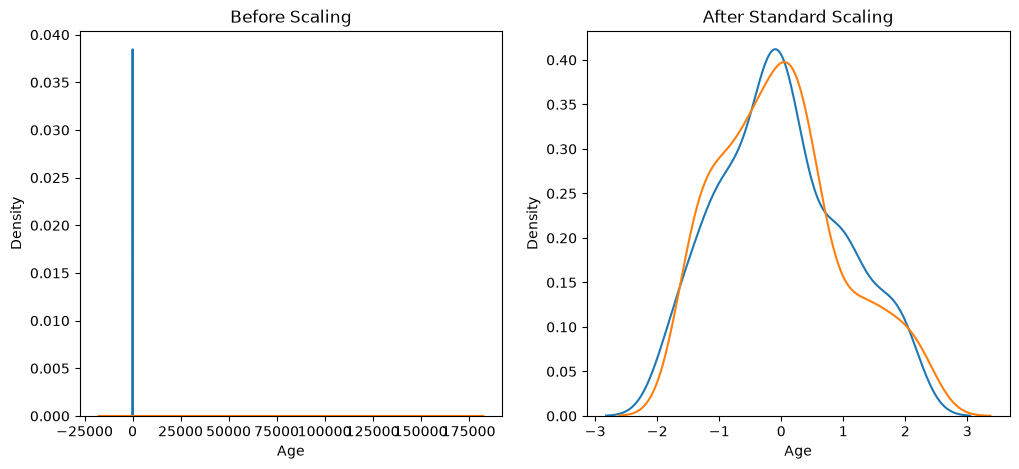

In [53]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1)
sns.kdeplot(X_train['EstimatedSalary'], ax=ax1)

# after scaling
ax2.set_title('After Standard Scaling')
sns.kdeplot(X_train_scaled['Age'], ax=ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax=ax2)

# comparison of Distribution

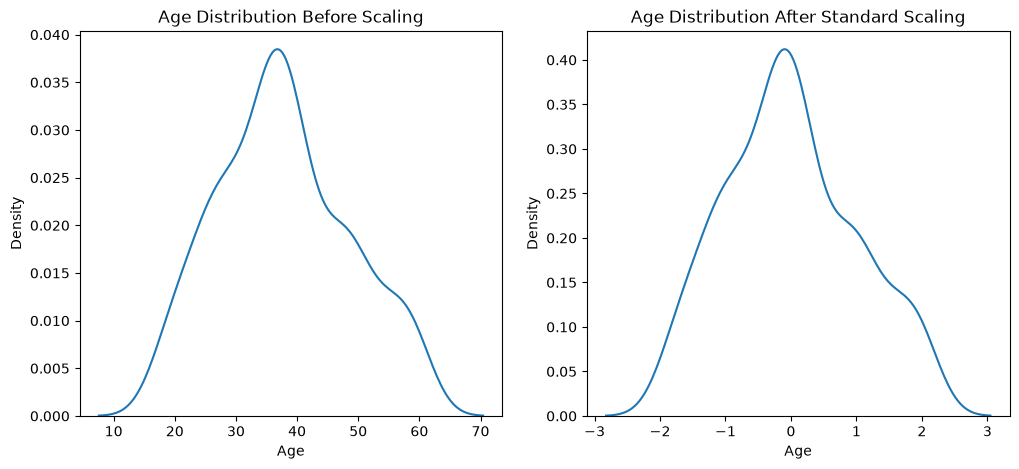

In [54]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Age Distribution Before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1)

# after scaling
ax2.set_title('Age Distribution After Standard Scaling')
sns.kdeplot(X_train_scaled['Age'], ax=ax2)
plt.show()

# why scaling is important?

In [55]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr_scaled = LogisticRegression()

lr.fit(X_train, y_train)
lr_scaled.fit(X_train_scaled, y_train)

# The output "LogisticRegression()" shown in the image is the result of the fit() method above.

y_pred = lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [56]:
from sklearn.metrics import accuracy_score

print("Actual", accuracy_score(y_test, y_pred))
print("Scaled", accuracy_score(y_test, y_pred_scaled))

Actual 0.8166666666666667
Scaled 0.8333333333333334


In [57]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt_scaled = DecisionTreeClassifier()

dt.fit(X_train, y_train)
dt_scaled.fit(X_train_scaled, y_train)

# DecisionTreeClassifier() - output from fitting

y_pred = dt.predict(X_test)
y_pred_scaled = dt_scaled.predict(X_test_scaled)

print("Actual", accuracy_score(y_test, y_pred))
print("Scaled", accuracy_score(y_test, y_pred_scaled))

Actual 0.8583333333333333
Scaled 0.85


In [58]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


# effect of outliers

In [61]:
df = pd.concat([df, pd.DataFrame({'Age': [5, 90, 95], 'EstimatedSalary': [1000, 250000, 350000], 'Purchased': [0, 1, 1]})], ignore_index=True)

In [62]:
df

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
398,36,33000,0
399,49,36000,1
400,5,1000,0
401,90,250000,1


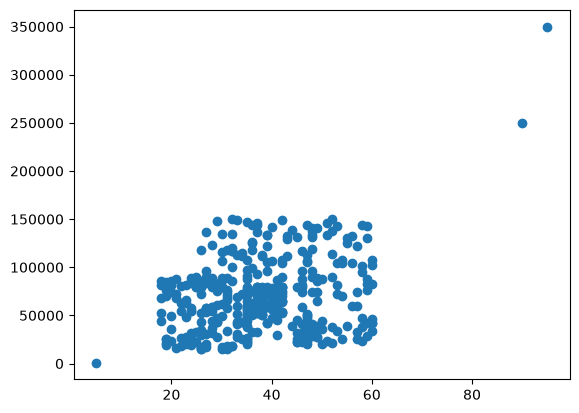

In [63]:
plt.scatter(df['Age'], df['EstimatedSalary'])

In [64]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Purchased', axis=1),
                                                    df['Purchased'],
                                                    test_size=0.3,
                                                    random_state=0)
X_train.shape, X_test.shape

((282, 2), (121, 2))

In [65]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [66]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

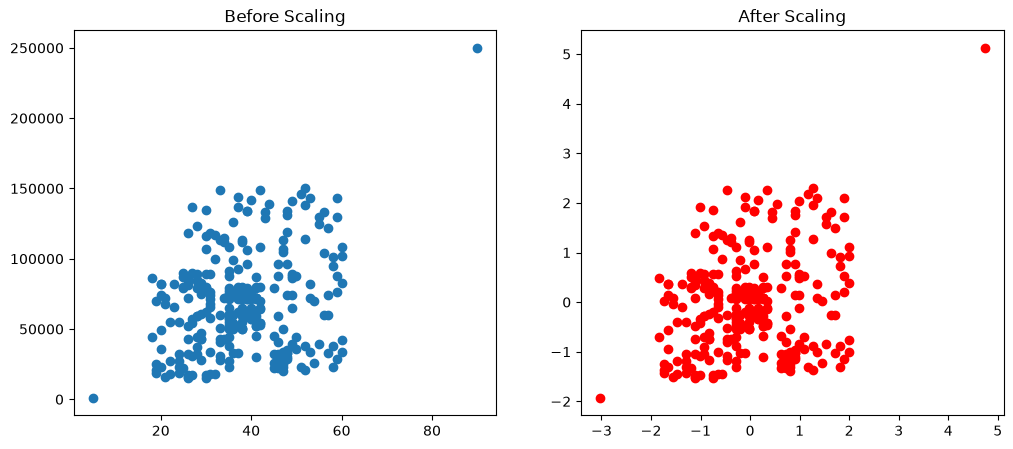

In [67]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color='red')
ax2.set_title("After Scaling")
plt.show()